# Motor de riesgo de un portafolio de acciones chilenas

Ejercicio educativo (no es asesoría financiera). Calculo el riesgo de un portafolio de 6 acciones chilenas con VaR y CVaR a 1 día por tres métodos: histórico, paramétrico (normal) y Monte Carlo.

Convenciones: retornos logarítmicos diarios, anualización con 250 días, VaR y CVaR a 1 día como pérdida positiva (no se anualizan). El detalle está en la cabecera de `riesgo.py`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import riesgo as rk
from riesgo import ACCIONES, INDICE, DIAS_ANIO

## 1. Datos

Precios ajustados desde 2018 de 6 acciones chilenas y del ETF que replica el IPSA (el índice `^IPSA` no descarga en Yahoo). El CSV queda guardado en `data/` con la fecha de descarga en el nombre.

In [2]:
# False usa el CSV que ya guardamos, True baja datos nuevos de Yahoo
FORZAR_DESCARGA = False

# Esto es para revisar si a alguna serie le faltan datos, y avisa cuál
px_raw, ruta_csv, reporte = rk.obtener_precios(forzar_descarga=FORZAR_DESCARGA)
print("\nArchivo:", ruta_csv)

# Rellena huecos chicos (máximo 3 días) con el último precio conocido
px, n_descartadas = rk.limpiar_precios(px_raw)
print(f"Filas descartadas en limpieza: {n_descartadas} de {len(px_raw)}")
assert n_descartadas / len(px_raw) < 0.02, "Se descartó más del 2% de las filas: revisar datos"

px_acc, px_ipsa = px[ACCIONES], px[INDICE]

r = rk.retornos_log(px)
r_acc, r_ipsa = r[ACCIONES], r[INDICE]

assert not r.isna().any().any(), "Hay NaN en los retornos"
assert np.isfinite(r.values).all(), "Hay inf en los retornos"
assert (px > 0).all().all(), "Hay precios <= 0"

# Movimientos de más de 25% en un día suelen ser errores de datos, hay que mirarlos a mano
saltos = rk.detectar_saltos(px)
print("\nSaltos diarios > 25% (revisar):")
print(saltos if len(saltos) else "ninguno")

print(f"\nPeriodo: {px.index.min().date()} a {px.index.max().date()} | {len(px)} días | {px.shape[1]} series")

                  primera      ultima n_obs pct_NaN          pmin           pmax
FALABELLA.SN   2018-01-02  2026-10-22  2190     0.0    1374.89624    6824.899902
COPEC.SN       2018-01-02  2026-10-22  2190     0.0   4024.636719   10273.201172
SQM-B.SN       2018-01-02  2026-10-22  2190     0.0  12827.795898  101933.257812
BCI.SN         2018-01-02  2026-10-22  2190     0.0  12266.074219        67751.0
CENCOSUD.SN    2018-01-02  2026-10-22  2190     0.0    404.625122     3309.97168
CMPC.SN        2018-01-02  2026-10-22  2190     0.0         957.0    2561.922119
CFMITNIPSA.SN  2018-01-02  2026-10-22  2189  0.0005   1955.569946    5527.100098

Archivo: data/precios_ajustados_2018-01-01_descarga_2026-10-23.csv
Filas descartadas en limpieza: 0 de 2190

Saltos diarios > 25% (revisar):
ninguno

Periodo: 2018-01-02 a 2026-10-22 | 2190 días | 7 series


## 2. Portafolios y normalidad

Dos portafolios: pesos iguales, y el de máximo Sharpe entre 50.000 combinaciones de pesos al azar (método del curso). Este último está optimizado con los mismos datos que evalúa, así que sus resultados son optimistas. La tasa libre de riesgo se deja en 0.

Resumen anual (retornos log, 250 días, rf = 0):
               retorno_anual  vol_anual  sharpe
Pesos iguales         0.0259     0.2364  0.1094
Máximo Sharpe         0.0893     0.2442  0.3656

Pesos:
              Pesos iguales  Máximo Sharpe
FALABELLA.SN          0.167          0.046
COPEC.SN              0.167          0.071
SQM-B.SN              0.167          0.178
BCI.SN                0.167          0.580
CENCOSUD.SN           0.167          0.103
CMPC.SN               0.167          0.023

Normalidad de los retornos diarios (curtosis en exceso: la normal vale 0):
               media_diaria  vol_diaria  asimetria  curtosis_exceso  \
Pesos iguales        0.0001      0.0149    -0.6277          10.9061   
Máximo Sharpe        0.0004      0.0154    -0.4901           7.4722   

                       JB  p_valor  
Pesos iguales  10992.4386      0.0  
Máximo Sharpe   5180.1592      0.0  

Peores 3 días del ETF del IPSA:
Date
2020-03-16   -0.1278
2020-03-18   -0.1043
2021-05-17   -0.09

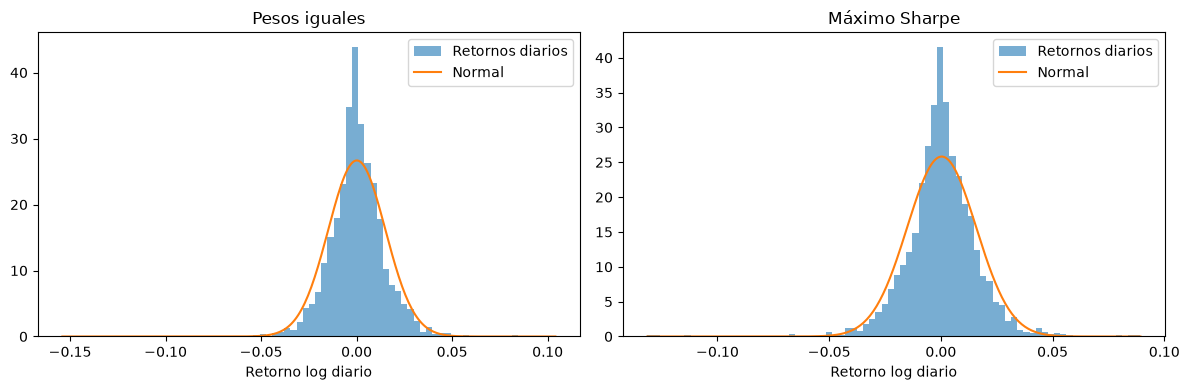

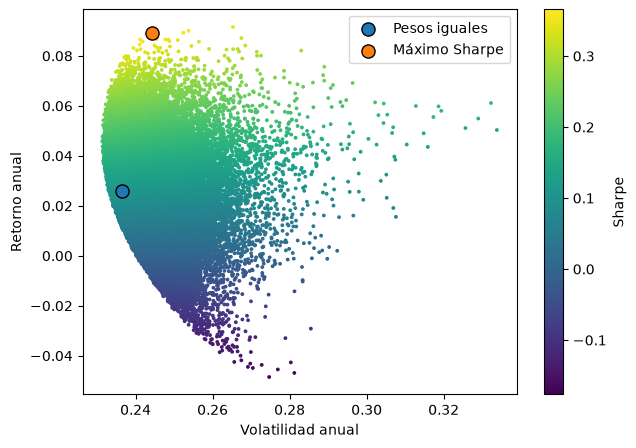

In [3]:
RF = 0.0        # tasa libre de riesgo anual: la dejo en 0 y lo aclaro en el README
N_SIM = 50_000
SEED = 42

mu, cov = rk.estadisticos_anuales(r_acc)
rk.validar_cov(cov)

# Dos portafolios: pesos iguales, y el de mayor Sharpe entre 50.000 combinaciones al azar
w_ew = np.repeat(1 / len(ACCIONES), len(ACCIONES))
W, rets_sim, vols_sim, sharpes_sim = rk.portafolios_aleatorios(mu, cov, N_SIM, RF, SEED)
w_ms = W[np.argmax(sharpes_sim)]
carteras = {"Pesos iguales": w_ew, "Máximo Sharpe": w_ms}

resumen, rp = {}, {}
for nombre, w in carteras.items():
    assert np.isclose(w.sum(), 1) and (w >= 0).all()
    ret, vol, sh = rk.metricas_portafolio(w, mu, cov, RF)
    assert 0 < vol <= np.sqrt(np.diag(cov)).max() + 1e-12   # no puede ser más volátil que el activo más volátil
    rp[nombre] = r_acc.dot(w)                                # retorno diario del portafolio
    assert np.isclose(vol, rp[nombre].std() * np.sqrt(DIAS_ANIO), rtol=1e-6)
    resumen[nombre] = {"retorno_anual": ret, "vol_anual": vol, "sharpe": sh}

print("Resumen anual (retornos log, 250 días, rf = 0):")
print(pd.DataFrame(resumen).T.round(4))
print("\nPesos:")
print(pd.DataFrame({"Pesos iguales": w_ew, "Máximo Sharpe": w_ms}, index=ACCIONES).round(3))

norm = pd.DataFrame({k: rk.test_normalidad(v) for k, v in rp.items()}).T
print("\nNormalidad de los retornos diarios (curtosis en exceso: la normal vale 0):")
print(norm.round(4))

# Revisión del ETF: sus peores días deberían caer en crisis conocidas
print("\nPeores 3 días del ETF del IPSA:")
print(r_ipsa.nsmallest(3).round(4))

os.makedirs("figuras", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nombre, s) in zip(axes, rp.items()):
    ax.hist(s, bins=80, density=True, alpha=0.6, label="Retornos diarios")
    x = np.linspace(s.min(), s.max(), 300)
    ax.plot(x, stats.norm.pdf(x, s.mean(), s.std()), label="Normal")
    ax.set_title(nombre)
    ax.set_xlabel("Retorno log diario")
    ax.legend()
plt.tight_layout()
plt.savefig("figuras/histograma_normalidad.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 5))
sc = plt.scatter(vols_sim, rets_sim, c=sharpes_sim, s=3, cmap="viridis")
plt.colorbar(sc, label="Sharpe")
for nombre, m in resumen.items():
    plt.scatter(m["vol_anual"], m["retorno_anual"], s=90, edgecolor="black", label=nombre)
plt.xlabel("Volatilidad anual")
plt.ylabel("Retorno anual")
plt.legend()
plt.savefig("figuras/portafolios_aleatorios.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. VaR y CVaR a 1 día

Tres métodos, al 95% y al 99%: histórico (percentil de los retornos reales), paramétrico (supone normal, usa `norm.ppf`) y Monte Carlo (100.000 días simulados de las 6 acciones juntas con `multivariate_normal`). Las pérdidas son números positivos.

In [4]:
N_SIM_MC = 100_000

resultados = {}
for nombre, w in carteras.items():
    x = rp[nombre].values
    sims = rk.simular_portafolio(r_acc, w, N_SIM_MC, SEED)
    tabla = rk.tabla_var(x, sims)
    # Monte Carlo y paramétrico parten del mismo supuesto (normal), así que deberían dar casi lo mismo
    assert abs(tabla.loc["Monte Carlo", "VaR 99%"] / tabla.loc["Paramétrico (normal)", "VaR 99%"] - 1) < 0.05
    resultados[nombre] = tabla
    print(f"\n=== {nombre}: VaR y CVaR a 1 día (pérdida positiva, en %) ===")
    print((tabla * 100).round(2))
    print("Días de la muestra con pérdida mayor al VaR, en % (esperado: 5% y 1%):")
    print((rk.tasa_excepciones(x, tabla) * 100).round(2))

os.makedirs("resultados", exist_ok=True)
pd.concat(resultados, names=["Portafolio", "Método"]).to_csv("resultados/var_cvar_1dia.csv")


=== Pesos iguales: VaR y CVaR a 1 día (pérdida positiva, en %) ===
                      VaR 95%  CVaR 95%  VaR 99%  CVaR 99%
Histórico                2.23      3.35     3.67      5.76
Paramétrico (normal)     2.45      3.07     3.47      3.97
Monte Carlo              2.44      3.07     3.46      3.97
Días de la muestra con pérdida mayor al VaR, en % (esperado: 5% y 1%):
                       95%   99%
Histórico             5.03  1.01
Paramétrico (normal)  3.88  1.32
Monte Carlo           3.88  1.32

=== Máximo Sharpe: VaR y CVaR a 1 día (pérdida positiva, en %) ===
                      VaR 95%  CVaR 95%  VaR 99%  CVaR 99%
Histórico                2.35      3.45     3.83      5.73
Paramétrico (normal)     2.50      3.15     3.56      4.08
Monte Carlo              2.51      3.15     3.55      4.08
Días de la muestra con pérdida mayor al VaR, en % (esperado: 5% y 1%):
                       95%   99%
Histórico             5.03  1.01
Paramétrico (normal)  4.25  1.42
Monte Carlo        

### Monte Carlo contra los retornos reales

Portafolio de pesos iguales. A la derecha el mismo gráfico con escala logarítmica, que deja ver las colas: los retornos reales llegan mucho más lejos que los simulados con la normal.

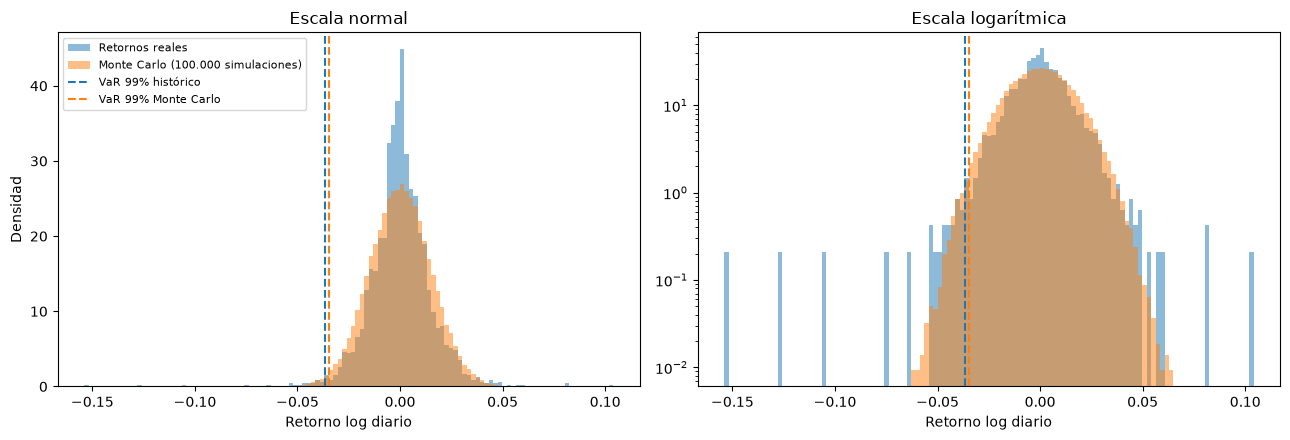

In [5]:
w = carteras["Pesos iguales"]
sims = rk.simular_portafolio(r_acc, w, N_SIM_MC, SEED)
x = rp["Pesos iguales"].values
tabla = resultados["Pesos iguales"]

bins = np.linspace(min(x.min(), sims.min()), max(x.max(), sims.max()), 120)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, escala in zip(axes, ["linear", "log"]):
    ax.hist(x, bins=bins, density=True, alpha=0.5, label="Retornos reales")
    ax.hist(sims, bins=bins, density=True, alpha=0.5, label=f"Monte Carlo ({N_SIM_MC:,} simulaciones)".replace(",", "."))
    ax.axvline(-tabla.loc["Histórico", "VaR 99%"], color="C0", ls="--", label="VaR 99% histórico")
    ax.axvline(-tabla.loc["Monte Carlo", "VaR 99%"], color="C1", ls="--", label="VaR 99% Monte Carlo")
    ax.set_yscale(escala)
    ax.set_xlabel("Retorno log diario")
    ax.set_title("Escala " + ("normal" if escala == "linear" else "logarítmica"))
axes[0].set_ylabel("Densidad")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figuras/montecarlo_vs_real.png", dpi=150, bbox_inches="tight")
plt.show()